<a href="https://colab.research.google.com/github/Mythrean2305/Clariqube/blob/main/Banana_Disease_AI_Model_and_API.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset"

print("Dataset exists:", os.path.exists(dataset_path))
print("Classes:", os.listdir(dataset_path))

Dataset exists: False


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BananaLeaf_AI/dataset'

In [ ]:
#Mythrean 1

from google.colab import drive
drive.mount('/content/drive')

import os

# Check dataset
dataset_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset"

print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Classes:", os.listdir(dataset_path))

# Check FastAPI folder
api_path = "/content/drive/MyDrive/BananaLeaf_AI/banana_api"

print("API folder exists:", os.path.exists(api_path))

if os.path.exists(api_path):
    print("API files:", os.listdir(api_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset exists: False
API folder exists: False


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Found 3001 files belonging to 3 classes.
Using 2401 files for training.
Found 3001 files belonging to 3 classes.
Using 600 files for validation.
Classes: ['Black_Sigatoka', 'Fusarium_Wilt', 'Healthy']
Training batches: 76
Validation batches: 19


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

# Load MobileNetV2 without its original classification layer
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

# Build our disease classification model
model = models.Sequential([
    data_augmentation,

    layers.Rescaling(1./255),

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax")
])

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model structure
model.summary()

TypeError: '<' not supported between instances of 'tuple' and 'int'

In [ ]:
# Fix IMG_SIZE for MobileNetV2
IMG_SIZE = 224

print("IMG_SIZE =", IMG_SIZE)

IMG_SIZE = 224


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

# Pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Build model
model = models.Sequential([
    data_augmentation,
    layers.Rescaling(1./255),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax")
])

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Train the model
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 1192s 16s/step - accuracy: 0.7609 - loss: 0.5590 - val_accuracy: 0.9067 - val_loss: 0.2391
Epoch 2/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 431s 6s/step - accuracy: 0.8992 - loss: 0.2617 - val_accuracy: 0.9367 - val_loss: 0.1667
Epoch 3/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 453s 6s/step - accuracy: 0.9192 - loss: 0.2221 - val_accuracy: 0.9433 - val_loss: 0.1425
Epoch 4/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 445s 6s/step - accuracy: 0.9225 - loss: 0.2018 - val_accuracy: 0.9350 - val_loss: 0.1523
Epoch 5/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 485s 6s/step - accuracy: 0.9379 - loss: 0.1710 - val_accuracy: 0.9383 - val_loss: 0.1326
Epoch 6/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 514s 7s/step - accuracy: 0.9454 - loss: 0.1512 - val_accuracy: 0.9517 - val_loss: 0.1073
Epoch 7/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 497s 7s/step - accuracy: 0.9429 - loss: 0.1508 - val_accuracy: 0.9400 - val_loss: 0.1087
Epoch 8/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 438s 6s/step - accuracy: 0.9550 - loss: 0.1339 - val_accuracy: 0.9450 -

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Evaluate the trained model on validation data
val_loss, val_accuracy = model.evaluate(val_ds, verbose=1)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)
print("Validation Accuracy (%):", val_accuracy * 100)

19/19 ━━━━━━━━━━━━━━━━━━━━ 83s 4s/step - accuracy: 0.9517 - loss: 0.1071
Validation Loss: 0.10709762573242188
Validation Accuracy: 0.9516666531562805
Validation Accuracy (%): 95.16666531562805


In [ ]:
# Predict disease for a new banana leaf image

import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

image_path = "/content/BS_77.jpg"

# Load and resize image
img = load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
img_array = img_to_array(img)

# Convert to batch and scale pixel values
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Predict
prediction = model.predict(img_array)

# Get predicted class
predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

print("Predicted Disease:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

NameError: name 'IMG_SIZE' is not defined

In [ ]:
# Save the trained model
model.save("/content/banana_disease_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
# Copy the trained model to Google Drive
import shutil

drive_model_path = "/content/drive/MyDrive/BananaLeaf_AI/banana_disease_model.keras"

shutil.copy(
    "/content/banana_disease_model.keras",
    drive_model_path
)

print("Model copied to Google Drive!")
print(drive_model_path)

Model copied to Google Drive!
/content/drive/MyDrive/BananaLeaf_AI/banana_disease_model.keras


In [ ]:
import os
import shutil

os.makedirs("/content/banana_api", exist_ok=True)

shutil.copy(
    "/content/banana_disease_model.keras",
    "/content/banana_api/banana_disease_model.keras"
)

print("Backend folder created!")
print("Model copied successfully!")

Backend folder created!
Model copied successfully!


In [ ]:
import os

os.makedirs("/content/banana_api", exist_ok=True)

print("banana_api folder created")

banana_api folder created


In [ ]:
%%writefile /content/banana_api/app.py

from fastapi import FastAPI, File, UploadFile
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel
from PIL import Image
import tensorflow as tf
import numpy as np
import io

app = FastAPI()

app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

model = tf.keras.models.load_model(
    "/content/banana_api/banana_disease_model.keras"
)

class_names = [
    "Black_Sigatoka",
    "Fusarium_Wilt",
    "Healthy"
]

IMG_SIZE = 224

@app.get("/")
def home():
    return {"message": "Banana Disease AI API is running"}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    image_bytes = await file.read()

    image = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    image = image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    image_array = np.array(image) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(
        image_array,
        verbose=0
    )

    predicted_index = int(
        np.argmax(prediction[0])
    )

    predicted_class = class_names[predicted_index]

    confidence = float(
        prediction[0][predicted_index] * 100
    )

    return {
        "disease": predicted_class,
        "confidence": round(confidence, 2)
    }


class SensorData(BaseModel):
    temperature: float
    humidity: float


latest_sensor_data = {
    "temperature": None,
    "humidity": None
}


@app.post("/sensor")
async def receive_sensor_data(data: SensorData):

    latest_sensor_data["temperature"] = data.temperature
    latest_sensor_data["humidity"] = data.humidity

    return {
        "status": "success",
        "temperature": data.temperature,
        "humidity": data.humidity
    }


@app.get("/sensor/latest")
def get_latest_sensor_data():

    return latest_sensor_data

Writing /content/banana_api/app.py


In [ ]:
!pip install fastapi uvicorn python-multipart

In [ ]:
!uvicorn banana_api.app:app --host 0.0.0.0 --port 8000

2026-08-09 14:40:59.482866: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
INFO:     Started server process [36315]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:48860 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:48868 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:36466 - "GET /docs HTTP/1.1" 200 OK
INFO:     127.0.0.1:36474 - "GET /openapi.json HTTP/1.1" 200 OK
INFO:     127.0.0.1:38426 - "POST /predict HTTP/1.1" 200 OK
INFO:     127.0.0.1:49964 - "POST /predict HTTP/1.1" 200 OK
INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [36315]
^C


In [ ]:
!pip install pyngrok -q

In [ ]:
from google.colab.output import eval_js

public_url = eval_js("google.colab.kernel.proxyPort(8000)")
print("Public URL:", public_url)

Public URL: https://8000-m-s-kkb-use4a0-165hr9k1gjxm4-a.us-east4-0.prod.colab.dev


In [ ]:
import shutil
import os

# Create folder in Google Drive
os.makedirs("/content/drive/MyDrive/BananaLeaf_AI/banana_api", exist_ok=True)

# Copy the API folder to Google Drive
shutil.copytree(
    "/content/banana_api",
    "/content/drive/MyDrive/BananaLeaf_AI/banana_api",
    dirs_exist_ok=True
)

print("banana_api saved to Google Drive successfully!")

banana_api saved to Google Drive successfully!


In [ ]:
import os

print("app.py:", os.path.exists("/content/banana_api/app.py"))
print("model:", os.path.exists("/content/banana_api/banana_disease_model.keras"))

app.py: True
model: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive/BananaLeaf_AI"))

['dataset', 'banana_disease_model.keras', 'banana_api']


In [ ]:
import shutil

shutil.copy(
    "/content/drive/MyDrive/BananaLeaf_AI/banana_disease_model.keras",
    "/content/banana_api/banana_disease_model.keras"
)

print("Model copied successfully")

Model copied successfully


In [ ]:
import os

print("app.py:", os.path.exists("/content/banana_api/app.py"))
print("model:", os.path.exists("/content/banana_api/banana_disease_model.keras"))

app.py: True
model: True


In [ ]:
!uvicorn banana_api.app:app --host 0.0.0.0 --port 8000

2026-08-10 14:27:57.659275: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-10 14:27:57.789228: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-10 14:28:02.952489: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
INFO:     Started server process [19712]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     Shutting down
INFO:     Finished server process [19712]
ERROR:    Traceback (most recent call last):
  File "/usr/lib/python3.12/asyncio/runners.py", l

In [ ]:
from google.colab import output

public_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print(public_url)

https://8000-m-s-kkb-use4a1-h00p64un8mk5-a.us-east4-1.prod.colab.dev


In [ ]:
import os

print(os.listdir("/content/banana_api"))

['banana_disease_model.keras', 'app.py', '__pycache__']


In [ ]:
!curl http://127.0.0.1:8000/

curl: (7) Failed to connect to 127.0.0.1 port 8000 after 0 ms: Connection refused


In [ ]:
%cd /content/banana_api

!uvicorn app:app --host 0.0.0.0 --port 8000

[Errno 2] No such file or directory: '/content/banana_api'
/content
ERROR:    Error loading ASGI app. Could not import module "app".


In [ ]:
from google.colab import output

public_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print(public_url)

https://8000-m-s-kkb-use4a1-h00p64un8mk5-a.us-east4-1.prod.colab.dev


In [ ]:
import subprocess
import sys

process = subprocess.Popen([
    sys.executable, "-m", "uvicorn",
    "app:app",
    "--host", "0.0.0.0",
    "--port", "8000"
])

print("FastAPI started in background.")

FastAPI started in background.


In [ ]:
from google.colab import output

public_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print(public_url)

https://8000-m-s-kkb-use4a1-h00p64un8mk5-a.us-east4-1.prod.colab.dev


In [ ]:
import subprocess
import sys

subprocess.Popen([
    sys.executable, "-m", "uvicorn",
    "app:app",
    "--host", "0.0.0.0",
    "--port", "8000"
])

print("FastAPI started in background.")

FastAPI started in background.


In [ ]:
from google.colab import output

public_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print(public_url)

https://8000-m-s-kkb-use4a1-h00p64un8mk5-a.us-east4-1.prod.colab.dev


In [ ]:
!curl http://127.0.0.1:8000/

{"message":"Banana Disease AI API is running"}

In [ ]:
!curl -I "https://8000-m-s-kkb-use4a1-h00p64un8mk5-a.us-east4-1.prod.colab.dev/"

HTTP/2 404 
cache-control: no-cache, no-store, max-age=0, must-revalidate
date: Mon, 10 Aug 2026 14:51:38 GMT
expires: Mon, 01 Jan 1990 00:00:00 GMT
pragma: no-cache
via: 1.1 google
alt-svc: h3=":443"; ma=2592000



In [ ]:
!curl "https://8000-m-s-kkb-use4a1-h00p64un8mk5-a.us-east4-1.prod.colab.dev/"

In [ ]:
import requests

url = "https://8000-m-s-kkb-use4a1-h00p64un8mk5-a.us-east4-1.prod.colab.dev/"

try:
    r = requests.get(url, timeout=10)
    print("Status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("ERROR:", e)

Status: 404
Response: 


In [ ]:
import requests

base = "https://8000-m-s-kkb-use4a1-h00p64un8mk5-a.us-east4-1.prod.colab.dev"

for path in ["/docs", "/openapi.json", "/"]:
    try:
        r = requests.get(base + path, timeout=10)
        print(path, "→", r.status_code)
    except Exception as e:
        print(path, "→ ERROR:", e)

/docs → 404
/openapi.json → 404
/ → 404


In [ ]:
from google.colab import output

public_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print(public_url)

https://8000-m-s-kkb-ass1a1-21tanjbz4bt4v-a.asia-southeast1-1.prod.colab.dev


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

In [ ]:
!nohup /content/cloudflared tunnel --url http://127.0.0.1:8000 > /content/cloudflared.log 2>&1 &

In [ ]:
import time
time.sleep(5)

!cat /content/cloudflared.log

cat: /content/cloudflared.log: No such file or directory


In [ ]:
import requests

url = "https://common-occasionally-wear-florists.trycloudflare.com/docs"

r = requests.get(url, timeout=20)

print("Status:", r.status_code)
print("URL:", r.url)

ConnectionError: HTTPSConnectionPool(host='common-occasionally-wear-florists.trycloudflare.com', port=443): Max retries exceeded with url: /docs (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x7eeb81a073b0>: Failed to resolve 'common-occasionally-wear-florists.trycloudflare.com' ([Errno -2] Name or service not known)"))

In [ ]:
!./cloudflared tunnel --url http://127.0.0.1:8000

/bin/bash: line 1: ./cloudflared: No such file or directory


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared

In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8000

/bin/bash: line 1: /content/cloudflared: Permission denied


In [ ]:
!chmod +x /content/cloudflared && ls -l /content/cloudflared

-rwxr-xr-x 1 root root 39278667 Jul 23 10:19 /content/cloudflared


In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8000

2026-08-11T13:15:28Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-11T13:15:28Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-11T13:15:34Z INF +--------------------------------------------------------------------------------------------+
2026-08-11T13:15:34Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-08-11T13:15:34Z INF |  https://psychological-dentists-add-treasurer.trycloud

In [ ]:
%cd /content/banana_api

!uvicorn app:app --host 0.0.0.0 --port 8000

[Errno 2] No such file or directory: '/content/banana_api'
/content
ERROR:    Error loading ASGI app. Could not import module "app".


In [ ]:
!ls -la /content

total 38376
drwxr-xr-x 1 root root     4096 Aug 11 13:12 .
drwxr-xr-x 1 root root     4096 Aug 11 13:02 ..
-rwxr-xr-x 1 root root 39278667 Jul 23 10:19 cloudflared
drwxr-xr-x 4 root root     4096 Jun  4 13:32 .config
drwxr-xr-x 1 root root     4096 Jun  4 13:32 sample_data


In [ ]:
!find /content -maxdepth 3 -type f \( -name "app.py" -o -name "*.py" \) | head -50

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!find /content/drive/MyDrive -maxdepth 4 -type f \( -name "app.py" -o -name "requirements.txt" \) | head -50

/content/drive/MyDrive/BananaLeaf_AI/banana_api/app.py


In [ ]:
!cp -r /content/drive/MyDrive/BananaLeaf_AI/banana_api /content/

In [ ]:
!ls -la /content/banana_api

total 9472
drwx------ 3 root root    4096 Aug 11 13:28 .
drwxr-xr-x 1 root root    4096 Aug 11 13:28 ..
-rw------- 1 root root    1313 Aug 11 13:28 app.py
-rw------- 1 root root 9678934 Aug 11 13:28 banana_disease_model.keras
drwx------ 2 root root    4096 Aug 11 13:28 __pycache__


In [ ]:
%cd /content/banana_api
!uvicorn app:app --host 0.0.0.0 --port 8000

/content/banana_api
2026-08-11 13:39:38.251660: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-11 13:39:38.327710: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-11 13:39:44.511103: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
INFO:     Started server process [9430]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process

In [ ]:
!chmod +x /content/cloudflared

In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8000

2026-08-11T13:35:25Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-11T13:35:25Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-11T13:35:30Z INF +--------------------------------------------------------------------------------------------+
2026-08-11T13:35:30Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-08-11T13:35:30Z INF |  https://suggestions-charter-kid-students.trycloudflar

In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8000

2026-08-11T13:41:20Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-11T13:41:20Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-11T13:41:26Z INF +--------------------------------------------------------------------------------------------+
2026-08-11T13:41:26Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-08-11T13:41:26Z INF |  https://boolean-protocols-ryan-neighbor.trycloudflare

In [ ]:
%cd /content/banana_api
!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

/content/banana_api


In [ ]:
!sleep 3; cat /content/uvicorn.log

2026-08-11 13:44:59.903031: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-11 13:44:59.970038: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-11 13:45:04.808767: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
INFO:     Started server process [10752]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8000

2026-08-11T14:03:11Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-11T14:03:11Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-11T14:03:16Z INF +--------------------------------------------------------------------------------------------+
2026-08-11T14:03:16Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-08-11T14:03:16Z INF |  https://resistant-conferences-ipod-arab.trycloudflare

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!find /content/drive/MyDrive -maxdepth 4 -type f \( -name "app.py" -o -name "requirements.txt" \) | head -50

/content/drive/MyDrive/BananaLeaf_AI/banana_api/app.py


In [ ]:
!cp -r /content/drive/MyDrive/BananaLeaf_AI/banana_api /content/

In [ ]:
!ls -la /content/banana_api

total 9472
drwx------ 3 root root    4096 Aug 11 13:28 .
drwxr-xr-x 1 root root    4096 Aug 11 13:44 ..
-rw------- 1 root root    1313 Aug 11 15:46 app.py
-rw------- 1 root root 9678934 Aug 11 15:46 banana_disease_model.keras
drwx------ 2 root root    4096 Aug 11 13:30 __pycache__


In [ ]:
%cd /content/banana_api
!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

/content/banana_api


In [ ]:
!sleep 3; cat /content/uvicorn.log

2026-08-11 15:46:34.923649: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-11 15:46:35.017820: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-11 15:46:41.412163: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
INFO:     Started server process [40069]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8000

2026-08-11T15:59:42Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-11T15:59:42Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-11T15:59:49Z INF +--------------------------------------------------------------------------------------------+
2026-08-11T15:59:49Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-08-11T15:59:49Z INF |  https://superintendent-meat-warming-celebrity.tryclou

In [ ]:
!grep -nE '@app\.(post|get|put|delete)' /content/banana_api/app.py

34:@app.get("/")
39:@app.post("/predict")


In [ ]:
!curl -X POST "http://127.0.0.1:8000/predict" \
  -F "file=@/content/banana_api/BS_75.jpg"

curl: (26) Failed to open/read local data from file/application


In [ ]:
!find /content -iname "BS_75.jpg"

/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg


In [ ]:
!find /content -type f \( -iname "*.jpg" -o -iname "*.jpeg" -o -iname "*.png" \) | head -20

/content/drive/MyDrive/IMG-20260409-WA0006.jpg
/content/drive/MyDrive/Screenshot_2026-05-21-15-49-33-38_6012fa4d4ddec268fc5c7112cbb265e7.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_640.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_442.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_495.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_683.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_668.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_132.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_50.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_481.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_654.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_78.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_697.jpg
/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_456.jpg
/content/

In [ ]:
!curl -X POST "http://127.0.0.1:8000/predict" \
  -F "file=@/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg"

curl: (7) Failed to connect to 127.0.0.1 port 8000 after 0 ms: Connection refused


In [ ]:
%cd /content/banana_api
!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

/content/banana_api


In [ ]:
!cat /content/uvicorn.log

ERROR:    Error loading ASGI app. Could not import module "app".


In [ ]:
!curl -X POST "http://127.0.0.1:8000/predict" \
  -F "file=@/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg"

curl: (26) Failed to open/read local data from file/application


In [ ]:
!cloudflared tunnel --url http://127.0.0.1:8000

2026-09-09T06:38:01Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-09-09T06:38:01Z INF Requesting new quick Tunnel on trycloudflare.com...
^C


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /usr/local/bin/cloudflared
!chmod +x /usr/local/bin/cloudflared
!cloudflared --version

cloudflared version 2026.8.3 (built 2026-08-31-10:04 UTC)


In [ ]:
!cloudflared tunnel --url http://127.0.0.1:8000

2026-09-09T05:20:55Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-09-09T05:20:55Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-09-09T05:20:59Z INF +--------------------------------------------------------------------------------------------+
2026-09-09T05:20:59Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-09-09T05:20:59Z INF |  https://side-atm-asia-ppm.trycloudflare.com          

In [ ]:
!curl -X POST "http://127.0.0.1:8000/predict" \
  -F "file=@/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg"

curl: (26) Failed to open/read local data from file/application


In [ ]:
%cd /content/banana_api
!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

[Errno 2] No such file or directory: '/content/banana_api'
/content


In [ ]:
!cat /content/uvicorn.log

cat: /content/uvicorn.log: No such file or directory


In [ ]:
!curl -X POST "http://127.0.0.1:8000/predict" \
  -F "file=@/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg"

curl: (26) Failed to open/read local data from file/application


In [ ]:
!curl -X POST "http://127.0.0.1:8000/predict" \
  -F "file=@/content/drive/MyDrive/IMG-20260409-WA0006.jpg"

curl: (26) Failed to open/read local data from file/application


In [ ]:
!sed -n '1,140p' /content/banana_api/app.py

sed: can't read /content/banana_api/app.py: No such file or directory


In [ ]:
!sed -n '35,100p' /content/banana_api/app.py

sed: can't read /content/banana_api/app.py: No such file or directory


In [ ]:
import numpy as np

print("Model output shape:", model.output_shape)

test = model.predict(image_array, verbose=0)

print("Raw probabilities:")
print(test[0])

print("Class names:")
print(class_names)

print("Predicted index:", np.argmax(test[0]))

NameError: name 'model' is not defined

In [ ]:
import tensorflow as tf
import numpy as np

model = tf.keras.models.load_model(
    "/content/banana_api/banana_disease_model.keras"
)

class_names = [
    "Black_Sigatoka",
    "Fusarium_Wilt",
    "Healthy"
]

print("Model output shape:", model.output_shape)
print("Model loaded successfully")

ValueError: File not found: filepath=/content/banana_api/banana_disease_model.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
test = model.predict(image_array, verbose=0)

print("Raw probabilities:")
print(test[0])

print("Class names:")
print(class_names)

print("Predicted index:", np.argmax(test[0]))

NameError: name 'model' is not defined

In [ ]:
from PIL import Image
import numpy as np

# Test image
image_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg"

# Load and preprocess exactly like your API
image = Image.open(image_path).convert("RGB")
image = image.resize((224, 224))

image_array = np.array(image) / 255.0
image_array = np.expand_dims(image_array, axis=0)

# Predict
test = model.predict(image_array, verbose=0)

print("Raw probabilities:")
print(test[0])

print("\nClass names:")
print(class_names)

print("\nPredicted index:", np.argmax(test[0]))
print("Predicted disease:", class_names[np.argmax(test[0])])

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg'

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset"

print(os.listdir(dataset_path))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BananaLeaf_AI/dataset'

In [ ]:
!grep -RniE "class_indices|flow_from_directory|image_dataset_from_directory|class_names" /content/drive/MyDrive/BananaLeaf_AI --include="*.ipynb" --include="*.py" | head -50

grep: /content/drive/MyDrive/BananaLeaf_AI: No such file or directory


In [ ]:
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

model.summary()

NameError: name 'model' is not defined

In [ ]:
!grep -RniE "class_names|class_indices|flow_from_directory|image_dataset_from_directory|train_ds|validation_ds|train_generator" /content/drive/MyDrive/BananaLeaf_AI --include="*.py" --include="*.ipynb" | head -100

grep: /content/drive/MyDrive/BananaLeaf_AI: No such file or directory


In [ ]:
!find /content/drive/MyDrive -type f \( -name "*.ipynb" -o -name "*.py" \) | grep -Ei "banana|disease|train|model" | head -100

find: ‘/content/drive/MyDrive’: No such file or directory


In [ ]:
import json

notebook_path = "/content/drive/MyDrive/Colab Notebooks/Banana Disease AI Model and API.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for cell in nb["cells"]:
    source = "".join(cell.get("source", []))
    if any(word in source.lower() for word in [
        "class_names",
        "flow_from_directory",
        "class_indices",
        "image_dataset_from_directory"
    ]):
        print("=" * 80)
        print(source)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Colab Notebooks/Banana Disease AI Model and API.ipynb'

In [ ]:
!find /content/drive -type f -name "*.ipynb" | grep -i "Banana"

find: ‘/content/drive’: No such file or directory


In [ ]:
import json

notebook_path = "/content/drive/MyDrive/Colab Notebooks/Banana_Disease_AI_Model_and_API.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for cell in nb["cells"]:
    source = "".join(cell.get("source", []))

    if any(word in source.lower() for word in [
        "class_names",
        "flow_from_directory",
        "class_indices",
        "image_dataset_from_directory"
    ]):
        print("=" * 80)
        print(source)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Colab Notebooks/Banana_Disease_AI_Model_and_API.ipynb'

In [ ]:
print("Class names from the training dataset:")
print(train_ds.class_names)

Class names from the training dataset:


NameError: name 'train_ds' is not defined

In [ ]:
import tensorflow as tf

dataset_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset"

temp_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

print("Class names:")
print(temp_ds.class_names)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BananaLeaf_AI/dataset'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls -lh /content/drive/MyDrive/BananaLeaf_AI/banana_api/

total 9.3M
-rw------- 1 root root 1.3K Aug  9 14:09 app.py
-rw------- 1 root root 9.3M Aug  9 14:08 banana_disease_model.keras
drwx------ 2 root root 4.0K Aug  9 14:10 __pycache__


In [ ]:
!rm -rf /content/banana_api
!cp -r /content/drive/MyDrive/BananaLeaf_AI/banana_api /content/banana_api
!ls -lh /content/banana_api

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
total 9.3M
-rw------- 1 root root 1.3K Sep  3 08:43 app.py
-rw------- 1 root root 9.3M Sep  3 08:43 banana_disease_model.keras
drwx------ 2 root root 4.0K Sep  3 08:43 __pycache__


In [ ]:
!pip install -q fastapi uvicorn python-multipart pillow numpy

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
The folder you are executing pip from can no longer be found.


In [ ]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [ ]:
import tensorflow as tf

model_path = "/content/banana_api/banana_disease_model.keras"

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)


In [ ]:
!grep -n -E "@app\.(get|post)|class_names|model.load_model" /content/banana_api/app.py

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
25:class_names = [
34:@app.get("/")
39:@app.post("/predict")
53:    predicted_class = class_names[predicted_index]


In [ ]:
%cd /content/banana_api

!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

/content/banana_api


In [ ]:
!cat /content/uvicorn.log

In [ ]:
!curl -X POST "http://127.0.0.1:8000/predict" \
  -F "file=@/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg"

curl: (7) Failed to connect to 127.0.0.1 port 8000 after 0 ms: Connection refused


In [ ]:
!curl -X POST "http://127.0.0.1:8000/predict" \
  -F "file=@/content/drive/MyDrive/IMG-20260409-WA0006.jpg"

curl: (7) Failed to connect to 127.0.0.1 port 8000 after 0 ms: Connection refused


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

In [ ]:
!/content/cloudflared --version

cloudflared version 2026.8.3 (built 2026-08-31-10:04 UTC)


In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8000

/bin/bash: line 1: /content/cloudflared: No such file or directory


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!find /content/drive/MyDrive -maxdepth 4 -type f \( -name "app.py" -o -name "requirements.txt" \) | head -50

In [ ]:
!cp -r /content/drive/MyDrive/BananaLeaf_AI/banana_api /content/

cp: cannot stat '/content/drive/MyDrive/BananaLeaf_AI/banana_api': No such file or directory


In [ ]:
!ls -la /content/banana_api

ls: cannot access '/content/banana_api': No such file or directory


In [ ]:
%cd /content/banana_api
!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

[Errno 2] No such file or directory: '/content/banana_api'
/content


In [ ]:
!sleep 3; cat /content/uvicorn.log

ERROR:    Error loading ASGI app. Could not import module "app".


In [ ]:
!/content/cloudflared tunnel --url http://127.0.0.1:8000

/bin/bash: line 1: /content/cloudflared: No such file or directory


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import shutil
import os

shutil.rmtree("/content/banana_api", ignore_errors=True)

shutil.copytree(
    "/content/drive/MyDrive/BananaLeaf_AI/banana_api",
    "/content/banana_api"
)

print(os.listdir("/content/banana_api"))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BananaLeaf_AI/banana_api'

In [ ]:
!pip install -q fastapi uvicorn python-multipart pillow

In [ ]:
%cd /content/banana_api

!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

/content/banana_api


In [ ]:
!cat /content/uvicorn.log

In [ ]:
from google.colab import output

public_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print(public_url)

https://8000-m-s-kkb-euw4b2-6tbgq18788tu-b.europe-west4-2.prod.colab.dev


In [ ]:
#mythrean 2
!ls -lah /content/drive/MyDrive

total 118M
-rw-------  1 root root 1.6M Feb 10  2026 'AdobeScan10Feb2026(1).pdf'
-rw-------  1 root root 825K Nov 11  2024 'Adobe Scan 11-Nov-2024.pdf'
-rw-------  1 root root 2.0M Aug 19  2025  AdobeScan19Aug2025.pdf
-rw-------  1 root root 231K Nov 22  2025  AdobeScan22Nov2025.pdf
-rw-------  1 root root 2.1M Oct 23  2025  AdobeScan23Oct2025.pdf
-rw-------  1 root root 631K Mar 24  2025 'AdobeScan24-Mar-2025 (1).pdf'
-rw-------  1 root root 631K Mar 24  2025  AdobeScan24-Mar-2025.pdf
-rw-------  1 root root 2.8M Mar  9  2025  ARDM.pdf
-rw-------  1 root root 114K Oct 14  2025  certificate.png
-rw-------  1 root root  41M Jan 27  2026 'claim_amount by procedure_code.pbix'
drwx------ 10 root root 4.0K Sep 19  2024  Classroom
drwx------  2 root root 4.0K May  1  2025 'Colab Notebooks'
-rw-------  1 root root 126K Aug 31 13:20 'Copy of Syllabus.pdf'
-rw-------  1 root root 1.6M Feb 10  2026  DAA1.pdf
-rw-------  1 root root 2.0M Apr 20 15:15 'DocScanner20Apr20268-44pm (1).pdf'
-rw-------

In [ ]:
#mythrean 3
!find /content/drive/MyDrive -maxdepth 5 -type f \( -name "app.py" -o -name "banana_disease_model.keras" \) | head -50

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [ ]:
import os

base = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base):
    if "banana_api" in dirs:
        print("FOUND:", os.path.join(root, "banana_api"))

In [ ]:
import shutil
import os

src = "/content/drive/MyDrive/BananaLeaf_AI/banana_api"
dst = "/content/banana_api"

shutil.rmtree(dst, ignore_errors=True)
shutil.copytree(src, dst)

print("Files:", os.listdir(dst))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BananaLeaf_AI/banana_api'

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print("Searching for banana_disease_model.keras...")

found = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "banana_disease_model.keras" in files:
        path = os.path.join(root, "banana_disease_model.keras")
        found.append(path)
        print("FOUND:", path)

if not found:
    print("MODEL NOT FOUND")

Searching for banana_disease_model.keras...
FOUND: /content/drive/MyDrive/BananaLeaf_AI/banana_disease_model.keras
FOUND: /content/drive/MyDrive/BananaLeaf_AI/banana_api/banana_disease_model.keras


In [ ]:
import os

print("Checking Colab files...")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if "banana" in file.lower() and file.endswith((".keras", ".h5")):
            print("FOUND:", os.path.join(root, file))

Checking Colab files...


In [ ]:
import os

print("Top-level folders in MyDrive:")

for item in os.listdir("/content/drive/MyDrive"):
    print(item)

Top-level folders in MyDrive:
Classroom
IMG-20241028-WA0012.jpg
IMG-20241028-WA0013.jpg
Adobe Scan 11-Nov-2024.pdf
Document from kamalesh.pdf
ARDM.pdf
IEEE Paperpresentation.pptx
AdobeScan24-Mar-2025 (1).pdf
AdobeScan24-Mar-2025.pdf
HACKTRONIX1.0[Abstract].pdf
HACKTRONIX1.0[Change Makers].pdf
Smart Street light-1.pdf
IMG-20250427-WA0001.jpg
Colab Notebooks
EnglishAssignmentKamaleshD.pdf
AdobeScan19Aug2025.pdf
SE_ASSIGNMENT-3.pdf
VILLAGE_PROJECT.pdf
DocScanner22Sept202510-17pm.pdf
IMG-20251005-WA0004.jpg
Screenshot from 2025-10-14 20-26-21.png
certificate.png
AdobeScan23Oct2025.pdf
AdobeScan22Nov2025.pdf
Module II - BRUTE FORCE AND DIVIDE-AND-CONQUER
YRC republic day (REGISTRATION) (Responses).gsheet
under_utilized_resources.pbix
ICU Vital Trend & Early Warning.pbix
Drug Interaction & Risk Analysis.pbix
claim_amount by procedure_code.pbix
AdobeScan10Feb2026(1).pdf
DAA1.pdf
YRC- quiz final (Responses).gsheet
PQT.pdf.adding
Untitled spreadsheet.gsheet
YRC- quiz (Responses).gsheet
YRC - dr

In [ ]:
import os

path = "/content/drive/MyDrive/BananaLeaf_AI"

if os.path.exists(path):
    print("BananaLeaf_AI EXISTS")
    print(os.listdir(path))
else:
    print("BananaLeaf_AI DOES NOT EXIST")

BananaLeaf_AI DOES NOT EXIST


In [ ]:
import os

print("Searching entire Colab storage for the model...")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".keras") or file.endswith(".h5"):
            print(os.path.join(root, file))

Searching entire Colab storage for the model...


In [ ]:
import os

print("Google Drive contents:")
for item in os.listdir("/content/drive/MyDrive"):
    print(item)

Google Drive contents:
Classroom
IMG-20241028-WA0012.jpg
IMG-20241028-WA0013.jpg
Adobe Scan 11-Nov-2024.pdf
Document from kamalesh.pdf
ARDM.pdf
IEEE Paperpresentation.pptx
AdobeScan24-Mar-2025 (1).pdf
AdobeScan24-Mar-2025.pdf
HACKTRONIX1.0[Abstract].pdf
HACKTRONIX1.0[Change Makers].pdf
Smart Street light-1.pdf
IMG-20250427-WA0001.jpg
Colab Notebooks
EnglishAssignmentKamaleshD.pdf
AdobeScan19Aug2025.pdf
SE_ASSIGNMENT-3.pdf
VILLAGE_PROJECT.pdf
DocScanner22Sept202510-17pm.pdf
IMG-20251005-WA0004.jpg
Screenshot from 2025-10-14 20-26-21.png
certificate.png
AdobeScan23Oct2025.pdf
AdobeScan22Nov2025.pdf
Module II - BRUTE FORCE AND DIVIDE-AND-CONQUER
YRC republic day (REGISTRATION) (Responses).gsheet
under_utilized_resources.pbix
ICU Vital Trend & Early Warning.pbix
Drug Interaction & Risk Analysis.pbix
claim_amount by procedure_code.pbix
AdobeScan10Feb2026(1).pdf
DAA1.pdf
YRC- quiz final (Responses).gsheet
PQT.pdf.adding
Untitled spreadsheet.gsheet
YRC- quiz (Responses).gsheet
YRC - drawing (

In [ ]:
import os

drive_path = "/content/drive/MyDrive"

print("Searching Google Drive...")
print("-" * 50)

found = False

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if (
            file.endswith(".keras")
            or file.endswith(".h5")
            or "banana" in file.lower()
            or "sigatoka" in file.lower()
            or "fusarium" in file.lower()
        ):
            print(os.path.join(root, file))
            found = True

if not found:
    print("No banana model or banana dataset files found in Google Drive.")

Searching Google Drive...
--------------------------------------------------
No banana model or banana dataset files found in Google Drive.


In [ ]:
import os

print("Searching for banana disease folders...")
print("-" * 50)

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for folder in dirs:
        name = folder.lower()

        if (
            "banana" in name
            or "sigatoka" in name
            or "fusarium" in name
            or "healthy" in name
        ):
            print(os.path.join(root, folder))

Searching for banana disease folders...
--------------------------------------------------


In [ ]:
dataset_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset"

In [ ]:
model.save("/content/banana_disease_model.keras")

NameError: name 'model' is not defined

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/AGRO_B_AI"
os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project folder created:", PROJECT_DIR)

Project folder created: /content/drive/MyDrive/AGRO_B_AI


In [ ]:
print(model)

NameError: name 'model' is not defined

In [ ]:
#197 1
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#197 2
import os

print(os.listdir("/content/drive/MyDrive"))


['Classroom', 'ASSIGNMENT I POLYMER CHEMISTRY (1).gdoc', 'ASSIGNMENT I POLYMER CHEMISTRY.gdoc', 'ChemAssign1.pdf', 'UNIT 1 - INTRODUCTION TO PROGRAMMING AND ALGORITHMS FOR PROBLEM SOLVING.gdoc', 'UNIT 2 - BASICS OF C PROGRAMMING.gdoc', 'Screenshot_2024-10-27-15-16-20-92_40deb401b9ffe8e1df2f1cc5ba480b12 (1).jpg', 'Screenshot_2024-10-27-15-16-20-92_40deb401b9ffe8e1df2f1cc5ba480b12.jpg', 'New LAB MANUAL PHYSICS 2024-2025 (FINAL1) (1) (1).gdoc', 'ASSIGNMENT 4 -CHEMICAL THERMODYNAMICS.gdoc', 'Maths Assign 4 (1).pdf', 'Maths Assign 4.pdf', 'EP LAB (ELECTRONICS) (1).gdoc', 'CHEMISTRY LAB MANUAL (1).gdoc', 'New LAB MANUAL PHYSICS 2024-2025 (FINAL1) (1).gdoc', 'CHEMISTRY LAB MANUAL.gdoc', 'UNIT 5 - STRUCTURES (1).gdoc', 'UNIT 6 - FILE PROCESSING (1).gdoc', 'UNIT 6 - FILE PROCESSING.gdoc', 'UNIT 5 - STRUCTURES.gdoc', 'eng assignment 1 (1).pdf', 'eng assignment 1.pdf', 'CAT I QB CEVS.gdoc', 'TEAM MJK.pptx', 'Quantum_Error_Detection_Presentation.pptx', 'posterforieee.png', '24CSPL302-DATASTRUCTURE

In [ ]:
#197 3
dataset_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset"

print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Classes:", os.listdir(dataset_path))

Dataset exists: True
Classes: ['Black_Sigatoka', 'Healthy', 'Fusarium_Wilt']


In [ ]:
#197 4
import tensorflow as tf

dataset_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset"

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

class_names = train_ds.class_names

print("Classes:", class_names)

Found 3001 files belonging to 3 classes.
Using 2401 files for training.
Found 3001 files belonging to 3 classes.
Using 600 files for validation.
Classes: ['Black_Sigatoka', 'Fusarium_Wilt', 'Healthy']


In [ ]:
#197 5
import tensorflow as tf
from tensorflow.keras import layers, models

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

# Load MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

# Build the model
model = models.Sequential([
    data_augmentation,
    layers.Rescaling(1./255),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax")
])

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Show model structure
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
#197 6
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Image size
IMG_SIZE = 224

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

# Pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Build model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1./255),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax")
])

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Build explicitly
model.build((None, 224, 224, 3))

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
#197 7
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 1811s 24s/step - accuracy: 0.7713 - loss: 0.5461 - val_accuracy: 0.9067 - val_loss: 0.2630
Epoch 2/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 439s 6s/step - accuracy: 0.9055 - loss: 0.2574 - val_accuracy: 0.9350 - val_loss: 0.1623
Epoch 3/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 435s 6s/step - accuracy: 0.9271 - loss: 0.2078 - val_accuracy: 0.9400 - val_loss: 0.1343
Epoch 4/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 429s 6s/step - accuracy: 0.9392 - loss: 0.1766 - val_accuracy: 0.9467 - val_loss: 0.1326
Epoch 5/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 434s 6s/step - accuracy: 0.9304 - loss: 0.1771 - val_accuracy: 0.9433 - val_loss: 0.1413
Epoch 6/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 439s 6s/step - accuracy: 0.9429 - loss: 0.1487 - val_accuracy: 0.9533 - val_loss: 0.1008
Epoch 7/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 435s 6s/step - accuracy: 0.9446 - loss: 0.1435 - val_accuracy: 0.9483 - val_loss: 0.1063
Epoch 8/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 429s 6s/step - accuracy: 0.9492 - loss: 0.1405 - val_accuracy: 0.9450 -

In [ ]:
#197 8
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print("Classification Report")
print("=" * 60)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix")
print(cm)

Classification Report
                precision    recall  f1-score   support

Black_Sigatoka     0.9534    0.9634    0.9583       191
 Fusarium_Wilt     0.9657    0.9471    0.9563       208
       Healthy     0.9901    1.0000    0.9950       201

      accuracy                         0.9700       600
     macro avg     0.9697    0.9702    0.9699       600
  weighted avg     0.9700    0.9700    0.9699       600


Confusion Matrix
[[184   7   0]
 [  9 197   2]
 [  0   0 201]]


In [ ]:
#197 9
# Save the trained model
model_path = "/content/banana_disease_model.keras"

model.save(model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: /content/banana_disease_model.keras


In [ ]:
#197 10
import shutil
import os

# Location where we want to save the model in Google Drive
drive_model_path = "/content/drive/MyDrive/BananaLeaf_AI/banana_disease_model.keras"

# Copy the trained model from Colab to Google Drive
shutil.copy(
    "/content/banana_disease_model.keras",
    drive_model_path
)

print("Model copied to Google Drive!")
print("Saved at:", drive_model_path)

Model copied to Google Drive!
Saved at: /content/drive/MyDrive/BananaLeaf_AI/banana_disease_model.keras


In [ ]:
#197 11
import os

api_path = "/content/banana_api"

os.makedirs(api_path, exist_ok=True)

print("API folder created:", api_path)

API folder created: /content/banana_api


In [ ]:
#197 12
%%writefile /content/banana_api/app.py

from fastapi import FastAPI, File, UploadFile
from fastapi.middleware.cors import CORSMiddleware
from PIL import Image
import tensorflow as tf
import numpy as np
import io

app = FastAPI()

# Allow frontend/mobile app to access the API
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

# Load trained model
model = tf.keras.models.load_model(
    "/content/banana_disease_model.keras"
)

# IMPORTANT: This order matches your training dataset
class_names = [
    "Black_Sigatoka",
    "Fusarium_Wilt",
    "Healthy"
]

IMG_SIZE = 224


@app.get("/")
def home():
    return {
        "message": "Banana Disease AI API is running"
    }


@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    image_bytes = await file.read()

    image = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    image = image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    image_array = np.array(image) / 255.0
    image_array = np.expand_dims(
        image_array, axis=0
    )

    prediction = model.predict(
        image_array,
        verbose=0
    )

    predicted_index = int(
        np.argmax(prediction[0])
    )

    predicted_class = class_names[predicted_index]

    confidence = float(
        prediction[0][predicted_index] * 100
    )

    return {
        "disease": predicted_class,
        "confidence": round(confidence, 2)
    }

Writing /content/banana_api/app.py


In [ ]:
#197 12
import sys

sys.path.insert(0, "/content/banana_api")

from app import app

print("FastAPI app loaded successfully!")

FastAPI app loaded successfully!


In [ ]:
#197 13
!pip install -q fastapi uvicorn python-multipart pillow

In [ ]:
#197 14 error
!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

In [ ]:
#197 15
%cd /content/banana_api

!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

/content/banana_api


In [ ]:
#197 16
!cat /content/uvicorn.log

2026-09-09 15:24:52.184495: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
INFO:     Started server process [38071]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


In [ ]:
#197 17
!curl http://127.0.0.1:8000/

{"message":"Banana Disease AI API is running"}

In [ ]:
#197 18 testing random image error
!curl -X POST "http://127.0.0.1:8000/predict" \
  -F "file=@/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg"

{"disease":"Fusarium_Wilt","confidence":99.65}

In [ ]:
#197 18
from PIL import Image
import numpy as np

image_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg"

image = Image.open(image_path).convert("RGB")
image = image.resize((224, 224))

image_array = np.array(image) / 255.0
image_array = np.expand_dims(image_array, axis=0)

prediction = model.predict(image_array, verbose=0)

print("Probabilities:")
for name, probability in zip(class_names, prediction[0]):
    print(f"{name}: {probability * 100:.2f}%")

print("\nPredicted:", class_names[np.argmax(prediction[0])])

Probabilities:
Black_Sigatoka: 0.31%
Fusarium_Wilt: 99.65%
Healthy: 0.04%

Predicted: Fusarium_Wilt


In [ ]:
#197 testing 5 random images
import os
import random
import numpy as np
from PIL import Image

for class_name in class_names:
    folder = f"/content/drive/MyDrive/BananaLeaf_AI/dataset/{class_name}"
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("\n" + "=" * 50)
    print("CLASS:", class_name)

    # Test 5 random images
    for filename in random.sample(images, min(5, len(images))):
        path = os.path.join(folder, filename)

        image = Image.open(path).convert("RGB")
        image = image.resize((224, 224))

        image_array = np.array(image) / 255.0
        image_array = np.expand_dims(image_array, axis=0)

        prediction = model.predict(image_array, verbose=0)[0]

        predicted_index = np.argmax(prediction)
        predicted_class = class_names[predicted_index]
        confidence = prediction[predicted_index] * 100

        print(
            f"{filename} → {predicted_class} "
            f"({confidence:.2f}%)"
        )


CLASS: Black_Sigatoka
BS_490.jpg → Fusarium_Wilt (99.63%)
BS_798.jpg → Fusarium_Wilt (99.63%)
BS_39.jpg → Fusarium_Wilt (99.63%)
BS_777.jpg → Fusarium_Wilt (99.64%)
BS_866.jpg → Fusarium_Wilt (99.63%)

CLASS: Fusarium_Wilt
FW_195.jpg → Fusarium_Wilt (99.62%)
FW_15.jpg → Fusarium_Wilt (99.63%)
FW_866.jpg → Fusarium_Wilt (99.62%)
FW_185.jpg → Fusarium_Wilt (99.62%)
FW_80.jpg → Fusarium_Wilt (99.62%)

CLASS: Healthy
HEALTHY_724.jpg → Fusarium_Wilt (99.63%)
HEALTHY_372.jpg → Fusarium_Wilt (99.63%)
HEALTHY_96.jpg → Fusarium_Wilt (99.62%)
HEALTHY_190.jpg → Fusarium_Wilt (99.62%)
HEALTHY_316.jpg → Fusarium_Wilt (99.62%)


In [ ]:
#197 checking
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total validation images:", len(y_true))
print("\nActual class counts:")
print(np.bincount(y_true))

print("\nPredicted class counts:")
print(np.bincount(y_pred, minlength=3))

print("\nClass names:")
print(class_names)

print("\nValidation accuracy:")
print(np.mean(y_true == y_pred))


Total validation images: 600

Actual class counts:
[191 208 201]

Predicted class counts:
[193 204 203]

Class names:
['Black_Sigatoka', 'Fusarium_Wilt', 'Healthy']

Validation accuracy:
0.97


In [ ]:
#197 checking the image files
from PIL import Image
import os

for class_name in class_names:
    folder = f"/content/drive/MyDrive/BananaLeaf_AI/dataset/{class_name}"

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("\n", class_name)

    for filename in files[:5]:
        path = os.path.join(folder, filename)

        try:
            img = Image.open(path)
            print(filename, "→", img.size, img.mode)
        except Exception as e:
            print(filename, "→ ERROR:", e)


 Black_Sigatoka
BS_640.jpg → (4624, 3468) RGB
BS_442.jpg → (4624, 3468) RGB
BS_495.jpg → (4624, 3468) RGB
BS_683.jpg → (4624, 3468) RGB
BS_668.jpg → (4624, 3468) RGB

 Fusarium_Wilt
FW_285.jpg → (4624, 3468) RGB
FW_520.jpg → (4624, 3468) RGB
FW_534.jpg → (4624, 3468) RGB
FW_939.jpg → (4624, 1680) RGB
FW_246.jpg → (4624, 3468) RGB

 Healthy
HEALTHY_428.jpg → (3982, 3468) RGB
HEALTHY_399.jpg → (3737, 3468) RGB
HEALTHY_825.jpg → (2962, 3468) RGB
HEALTHY_831.jpg → (3232, 3059) RGB
HEALTHY_366.jpg → (3468, 3929) RGB


In [ ]:
#197 testing 2
from PIL import Image
import numpy as np

image_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg"

image = Image.open(image_path).convert("RGB")
image = image.resize((224, 224))

# IMPORTANT: Do NOT divide by 255 here.
image_array = np.array(image, dtype=np.float32)
image_array = np.expand_dims(image_array, axis=0)

prediction = model.predict(image_array, verbose=0)[0]

print("Probabilities:")
for name, probability in zip(class_names, prediction):
    print(f"{name}: {probability * 100:.2f}%")

print("\nPredicted:", class_names[np.argmax(prediction)])

Probabilities:
Black_Sigatoka: 62.50%
Fusarium_Wilt: 37.47%
Healthy: 0.03%

Predicted: Black_Sigatoka


In [ ]:
#197 rewriting the app.py
%%writefile /content/banana_api/app.py

from fastapi import FastAPI, File, UploadFile
from fastapi.middleware.cors import CORSMiddleware
from PIL import Image
import tensorflow as tf
import numpy as np
import io

app = FastAPI()

app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

model = tf.keras.models.load_model(
    "/content/banana_disease_model.keras"
)

class_names = [
    "Black_Sigatoka",
    "Fusarium_Wilt",
    "Healthy"
]

IMG_SIZE = 224

@app.get("/")
def home():
    return {"message": "Banana Disease AI API is running"}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    image_bytes = await file.read()

    image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
    image = image.resize((IMG_SIZE, IMG_SIZE))

    # IMPORTANT: Do NOT divide by 255 here.
    # The model already contains Rescaling(1./255).
    image_array = np.array(image, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_array, verbose=0)[0]

    predicted_index = int(np.argmax(prediction))
    predicted_class = class_names[predicted_index]
    confidence = float(prediction[predicted_index] * 100)

    return {
        "disease": predicted_class,
        "confidence": round(confidence, 2)
    }

Overwriting /content/banana_api/app.py


In [ ]:
#197 19 restarting fastapi
!pkill -f "uvicorn app:app" || true

%cd /content/banana_api

!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

^C
/content/banana_api


In [ ]:
#197 19
!nohup uvicorn app:app --host 0.0.0.0 --port 8000 > /content/uvicorn.log 2>&1 &

In [ ]:
#197 19 verifying the above command
!cat /content/uvicorn.log

2026-09-09 15:44:08.650805: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
INFO:     Started server process [44021]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


In [ ]:
#197 killing the server again run 19 19.1
!pkill -f "uvicorn"

In [ ]:
#197 testing
import requests

image_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg"

with open(image_path, "rb") as f:
    response = requests.post(
        "http://127.0.0.1:8000/predict",
        files={"file": ("BS_75.jpg", f, "image/jpeg")}
    )

print(response.status_code)
print(response.json())

200
{'disease': 'Black_Sigatoka', 'confidence': 62.5}


In [ ]:
#197 3 class fastapi error
import requests
import os

test_images = {
    "Black_Sigatoka": "/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/BS_75.jpg",
    "Fusarium_Wilt": "/content/drive/MyDrive/BananaLeaf_AI/dataset/Fusarium_Wilt/FW_75.jpg",
    "Healthy": "/content/drive/MyDrive/BananaLeaf_AI/dataset/Healthy/H_75.jpg"
}

for actual_class, image_path in test_images.items():

    print("=" * 60)
    print("Actual class:", actual_class)
    print("Image:", os.path.basename(image_path))

    with open(image_path, "rb") as f:
        response = requests.post(
            "http://127.0.0.1:8000/predict",
            files={"file": (os.path.basename(image_path), f, "image/jpeg")}
        )

    print("Status:", response.status_code)
    print("API result:", response.json())

Actual class: Black_Sigatoka
Image: BS_75.jpg
Status: 200
API result: {'disease': 'Black_Sigatoka', 'confidence': 62.5}
Actual class: Fusarium_Wilt
Image: FW_75.jpg
Status: 200
API result: {'disease': 'Fusarium_Wilt', 'confidence': 94.51}
Actual class: Healthy
Image: H_75.jpg


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BananaLeaf_AI/dataset/Healthy/H_75.jpg'

In [ ]:
#197 error creation
import requests
import os
import glob

base_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset"

classes_to_test = [
    "Black_Sigatoka",
    "Fusarium_Wilt",
    "Healthy"
]

for actual_class in classes_to_test:

    image_files = glob.glob(
        os.path.join(base_path, actual_class, "*")
    )

    if not image_files:
        print(f"No images found for {actual_class}")
        continue

    image_path = image_files[0]

    print("=" * 60)
    print("Actual class:", actual_class)
    print("Image:", os.path.basename(image_path))

    with open(image_path, "rb") as f:
        response = requests.post(
            "http://127.0.0.1:8000/predict",
            files={
                "file": (
                    os.path.basename(image_path),
                    f,
                    "image/jpeg"
                )
            }
        )

    print("Status:", response.status_code)
    print("API result:", response.json())

Actual class: Black_Sigatoka
Image: BS_640.jpg
Status: 200
API result: {'disease': 'Black_Sigatoka', 'confidence': 98.41}
Actual class: Fusarium_Wilt
Image: FW_285.jpg
Status: 200
API result: {'disease': 'Fusarium_Wilt', 'confidence': 99.51}
Actual class: Healthy
Image: HEALTHY_428.jpg
Status: 200
API result: {'disease': 'Healthy', 'confidence': 99.97}


In [ ]:
#197 TESTINGGGGGGGG

import requests
import glob
import os

image_path = glob.glob(
    "/content/drive/MyDrive/BananaLeaf_AI/dataset/Black_Sigatoka/*"
)[0]

print("Testing image:", os.path.basename(image_path))

with open(image_path, "rb") as f:
    response = requests.post(
        "http://127.0.0.1:8000/predict",
        files={"file": (os.path.basename(image_path), f, "image/jpeg")}
    )

print("Status:", response.status_code)
print("Prediction:", response.json())

Testing image: BS_640.jpg
Status: 200
Prediction: {'disease': 'Black_Sigatoka', 'confidence': 98.41}


In [ ]:
#197 model loader
import tensorflow as tf

model_path = "/content/drive/MyDrive/BananaLeaf_AI/banana_disease_model.keras"

model = tf.keras.models.load_model(model_path)

class_names = [
    "Black_Sigatoka",
    "Fusarium_Wilt",
    "Healthy"
]

print("Model loaded successfully!")

Model loaded successfully!


Saving StockCake-Complex_Data_Visualization-643457-medium.jpg to StockCake-Complex_Data_Visualization-643457-medium.jpg


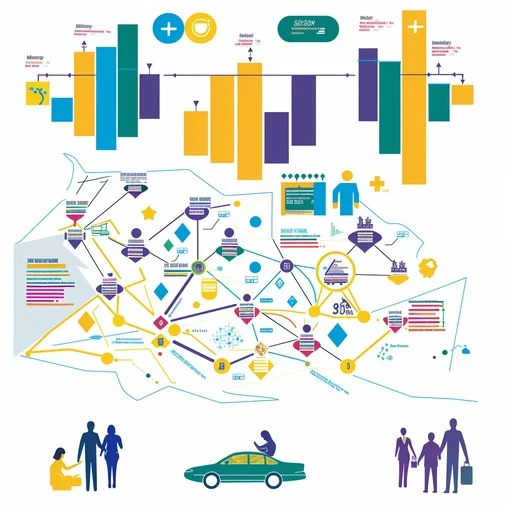


🍌 BANANA DISEASE AI RESULT
Prediction : Black_Sigatoka
Confidence : 53.13%

All probabilities:
Black_Sigatoka      : 53.13%
Fusarium_Wilt       : 25.30%
Healthy             : 21.57%


In [ ]:
#197 testingggggg2
from google.colab import files
from PIL import Image
import numpy as np
from IPython.display import display

# Upload an image
uploaded = files.upload()

# Get uploaded filename
filename = next(iter(uploaded))

# Open image
image = Image.open(filename).convert("RGB")

# Display image
display(image)

# Resize to model input size
image_resized = image.resize((224, 224))

# IMPORTANT: Do NOT divide by 255.
# The model already contains Rescaling(1./255).
image_array = np.array(image_resized, dtype=np.float32)
image_array = np.expand_dims(image_array, axis=0)

# Prediction
prediction = model.predict(image_array, verbose=0)[0]

predicted_index = np.argmax(prediction)
predicted_class = class_names[predicted_index]
confidence = prediction[predicted_index] * 100

print("\n🍌 BANANA DISEASE AI RESULT")
print("=" * 40)
print(f"Prediction : {predicted_class}")
print(f"Confidence : {confidence:.2f}%")
print("=" * 40)

print("\nAll probabilities:")
for name, probability in zip(class_names, prediction):
    print(f"{name:20s}: {probability * 100:.2f}%")

In [ ]:
# #197 unknown image identification
# import os

# base_path = "/content/drive/MyDrive/BananaLeaf_AI/dataset"

# for class_name in ["Black_Sigatoka", "Fusarium_Wilt", "Healthy"]:
#     folder = os.path.join(base_path, class_name)
#     files = os.listdir(folder)

#     print(class_name, ":", len(files), "images")

Black_Sigatoka : 1001 images
Fusarium_Wilt : 1002 images
Healthy : 1001 images


In [ ]:
# #197 non banana images
# import tensorflow as tf

# # Download CIFAR-10 (contains cars, animals, etc.)
# (x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# print("Non-banana images available:", len(x_train))
# print("Image shape:", x_train.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2458s 14us/step
Non-banana images available: 50000
Image shape: (50000, 32, 32, 3)


In [ ]:
# #197 nb
# import numpy as np

# # Use a small number of non-banana images for the detector
# non_banana_images = x_train[:3000].astype("float32")

# print("Non-banana images selected:", len(non_banana_images))
# print("Shape:", non_banana_images.shape)

Non-banana images selected: 3000
Shape: (3000, 32, 32, 3)


In [ ]:
# #197 nb
# import tensorflow as tf

# (x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# print("Loaded:", x_train.shape)

Loaded: (50000, 32, 32, 3)


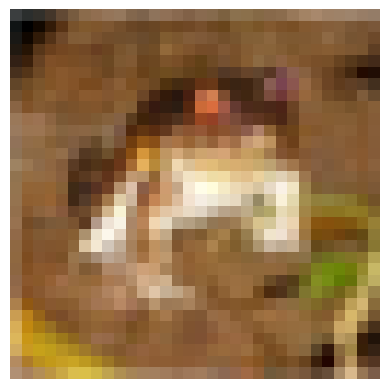

Model prediction:
Black_Sigatoka: 82.11%
Fusarium_Wilt: 17.50%
Healthy: 0.39%

Predicted: Black_Sigatoka


In [ ]:
# #197 nb
# import numpy as np
# import matplotlib.pyplot as plt

# # Pick one non-banana image
# random_image = x_train[0]

# plt.imshow(random_image)
# plt.axis("off")
# plt.show()

# # Resize to model input
# from PIL import Image

# image = Image.fromarray(random_image)
# image = image.resize((224, 224))

# # IMPORTANT: model already has Rescaling(1./255)
# image_array = np.array(image, dtype=np.float32)
# image_array = np.expand_dims(image_array, axis=0)

# prediction = model.predict(image_array, verbose=0)[0]

# print("Model prediction:")
# for name, probability in zip(class_names, prediction):
#     print(f"{name}: {probability * 100:.2f}%")

# print("\nPredicted:", class_names[np.argmax(prediction)])